# Reinforcing feedback, path dependence and lock-in in Python

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/waelrash1/loopbricks/blob/main/notebooks/08-lock-in.ipynb)

This notebook is the Python companion to the [Reinforcing feedback, path dependence and lock-in](https://waelrash1.github.io/loopbricks/#/learn/lock-in) module. You will see how a reinforcing loop magnifies small differences, how a network effect lets an early leader take a whole market, how to read which outcomes are stable from a single picture, and how pure chance can decide the winner. It uses the LoopBricks molecules Population Growth, Split Flow and Market Share, plus a small random experiment (a Polya urn) in plain Python.

In [1]:
# Run this cell first. In Colab it installs the loopbricks package, which takes about ten seconds.
try:
    import loopbricks as lb
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "loopbricks @ git+https://github.com/waelrash1/loopbricks.git@main#subdirectory=python"])
    import loopbricks as lb
import matplotlib.pyplot as plt
print("loopbricks", lb.__version__, "with molecules:", ", ".join(lb.molecules()))

loopbricks 0.1.0 with molecules: abilityFromAction, actionFromResource, aging, agingPDY, backlogFlow, backlogLevel, bathtub, broken, buildingInventory, capacityUtil, cascade, cascadeProtByPDY, cascadedCoflow, ceiling, closegap, coflow, coflowExperience, conversion, decay, desiredWorkforce, diffusion, doingWork, doingWorkCascade, effectFatigue, effectFunction, estCompletion, estProductivity, estRemaining, extrapolation, financialFlow, floor, goToZero, growth, logistic, lowVisPipeline, marketshare, material, multiSplit, multivariateAnchor, nonlinearSplit, overtime, presentValue, prodFatigue, producing, productivity, propSplit, protByPDY, protFlow, protLevel, protSeaAnchorPricing, protectedSeaAnchor, quality, reducingBacklog, residence, resourcesFromAction, reworkCycle, schedulePressure, seaAnchor, seaAnchorPricing, shiftingBurden, smooth, smoothHigher, smoothPricing, split, stockAdjust, stockmgmt, tragedyCommons, trend, univariateAnchor, weightedAvg, weightedSplit, workforce, workforceFr

## 1. Reinforcing loops magnify small differences

A reinforcing loop grows in proportion to what is already there, so a small edge in the growth rate becomes a large gap in size. Take two firms in **Population Growth** (read population as customers): both start with 100 and lose 2% a year, but one gains 5% a year and the other 6%.

year   10:    135 against    149, a gap of    14
year   30:    246 against    331, a gap of    86
year   60:    603 against   1097, a gap of   494


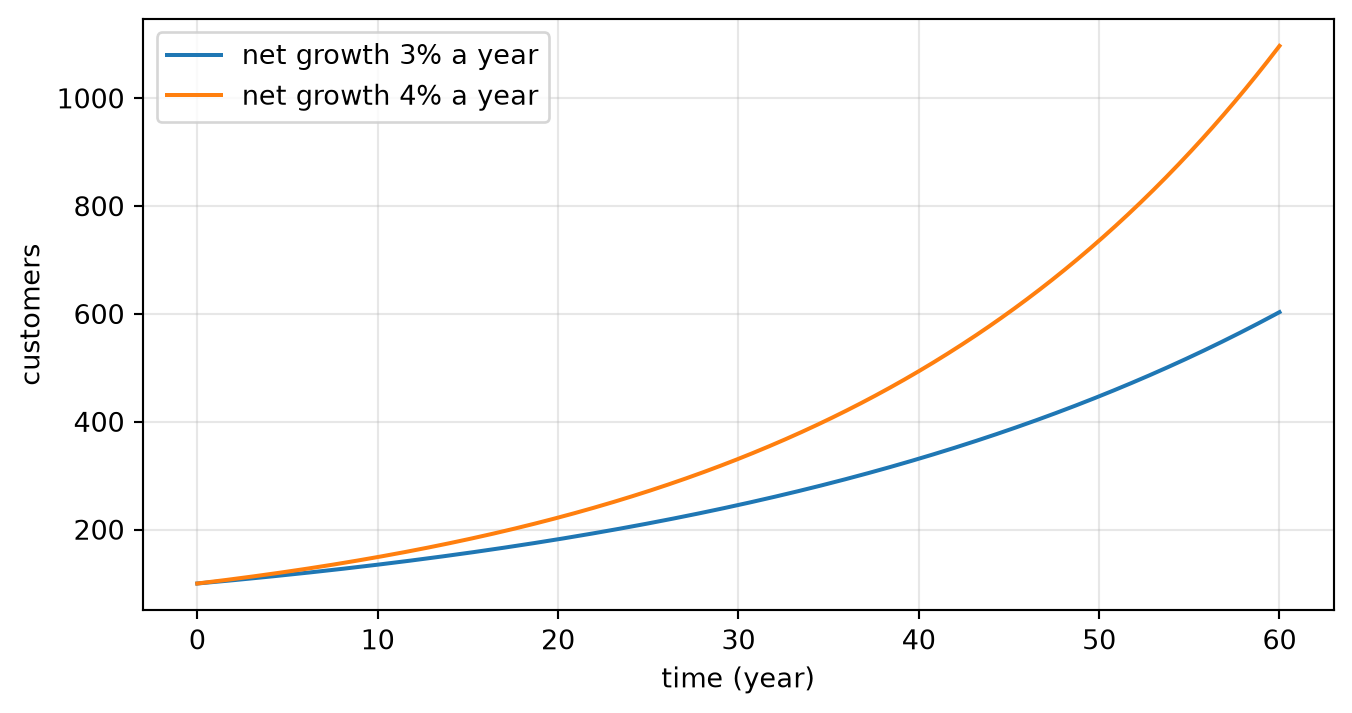

In [2]:
pg = lb.molecule("growth")
slow = pg.run(birth_rate=5)["Population"]
fast = pg.run(birth_rate=6)["Population"]

fig, ax = plt.subplots(figsize=(8, 4))
slow.plot(ax=ax, label="net growth 3% a year"); fast.plot(ax=ax, label="net growth 4% a year")
ax.set_ylabel("customers"); ax.legend(); ax.grid(alpha=0.3)

for t in (10.0, 30.0, 60.0):
    print(f"year {t:>4.0f}: {slow[t]:6.0f} against {fast[t]:6.0f}, a gap of {fast[t] - slow[t]:5.0f}")

After 10 years the two firms are almost level (135 against 149). After 60 years the faster one is nearly twice the size, and the gap keeps widening. But here each firm grows on its own: neither takes customers from the other. Lock-in needs one more thing, which is competition for the *same* customers, where one firm's success makes the other less attractive.

**Try it.** Run both firms for 100 years (`T=100`). In which year is the faster firm first twice as big as the slower one?

<details><summary>Show a worked answer</summary>

A gap of one percentage point in growth doubles the ratio between them every ln 2 / 0.01 ≈ 69 years. The run below gives year 69.6. A tiny edge, given enough time, becomes a decisive one.
</details>

In [3]:
slow = pg.run(T=100, birth_rate=5)["Population"]
fast = pg.run(T=100, birth_rate=6)["Population"]
print("The faster firm is first twice as big in year", (fast / slow)[fast / slow >= 2].index[0])

The faster firm is first twice as big in year 69.6


## 2. Competing for the same customers

In **Split Flow**, a stream of new customers is divided by a fixed rule, 60% to A and 40% to B. Nothing about the past matters: the shares end up 60/40 because the rule says so.

In **Market Share**, 20 new customers arrive each month and choose between two products, and customers leave after 18 months on average. A product becomes more attractive the more users it already has (a *network effect*), so the share of newcomers it wins depends on its installed base. Product A starts with 105 users and B with 95: a 52.5% share.

Split Flow at the end: A 42, B 28  (set by the rule)

Market Share

Stocks:
  Product A = INTEG(Wins to A − Churn A, 105)
  Product B = INTEG(Wins to B − Churn B, 95)

Flows:
  Wins to A = New_customers * Share_of_A
  Wins to B = New_customers * (1 - Share_of_A)
  Churn A = Product_A / Churn_time
  Churn B = Product_B / Churn_time

Variables:
  New customers = 20
  Network effect = 0.7
  Churn time = 18
  Attractiveness exponent = 1 + 2 * Network_effect
  Attractiveness A = Product_A ^ Attractiveness_exponent
  Attractiveness B = Product_B ^ Attractiveness_exponent
  Share of A = Attractiveness_A / (Attractiveness_A + Attractiveness_B + 0.000000001) 

network effect 0   : A holds 52% in month 24 and 52% in month 60
network effect 0.35: A holds 59% in month 24 and 78% in month 60
network effect 0.7 : A holds 72% in month 24 and 96% in month 60
network effect 1   : A holds 82% in month 24 and 98% in month 60


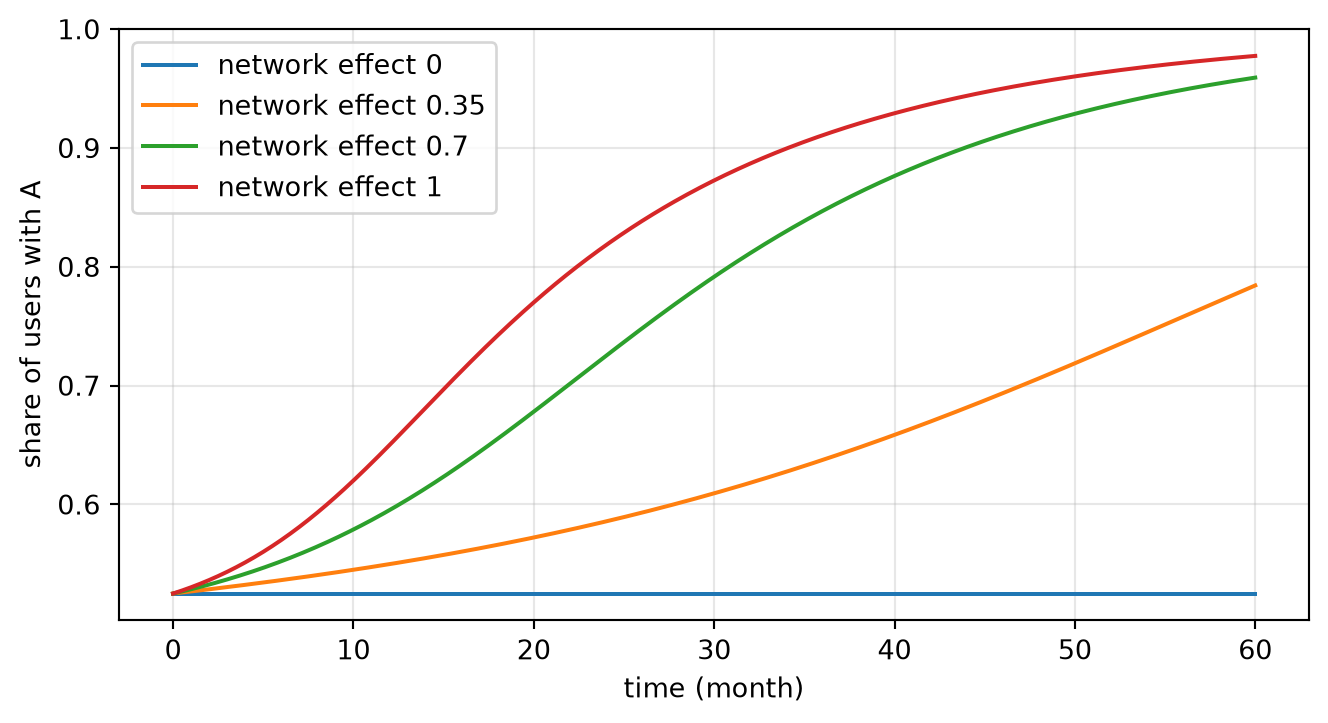

In [4]:
sp = lb.molecule("split").run()
print(f"Split Flow at the end: A {sp['Channel A'].iloc[-1]:.0f}, B {sp['Channel B'].iloc[-1]:.0f}  (set by the rule)\n")

ms = lb.molecule("marketshare")
print(ms.equations(), "\n")
fig, ax = plt.subplots(figsize=(8, 4))
for n in (0, 0.35, 0.7, 1):
    run = ms.run(network_effect=n)
    share = run["Product A"] / (run["Product A"] + run["Product B"])
    share.plot(ax=ax, label=f"network effect {n}")
    print(f"network effect {n:<4}: A holds {100 * share[24.0]:.0f}% in month 24 and {100 * share.iloc[-1]:.0f}% in month 60")
ax.set_ylabel("share of users with A"); ax.legend(); ax.grid(alpha=0.3)

With no network effect, A keeps the 52.5% it started with, for ever. With any network effect the early leader pulls away: at 0.7 its share climbs to 96% within five years, and at 1 to 98%. Nothing about A is better except that it was slightly ahead at the start. That is **path dependence**: where the system ends up depends on where it happened to begin.

**Try it.** With the default network effect of 0.7, start the race at 100 each, at 101 against 99, and at 95 against 105. What share does A end with? (A model's starting values live in its spec, so copy the spec and change the `init` of the two stocks.)

<details><summary>Show a worked answer</summary>

At exactly 100 each, the shares stay at 50%: a perfect tie is an equilibrium. A single-user lead (101 against 99) grows into an 87.5% share by month 60, and starting 95 against 105 leaves A with only 4%. The model does not care which product is which; it amplifies whichever one is ahead.
</details>

In [5]:
import copy

def race(a, b):
    spec = copy.deepcopy(ms.spec)
    spec["model"]["stocks"][0]["init"] = str(a)   # Product A
    spec["model"]["stocks"][1]["init"] = str(b)   # Product B
    run = lb.Model.from_spec(spec).run()
    return run["Product A"].iloc[-1] / (run["Product A"].iloc[-1] + run["Product B"].iloc[-1])

for a, b in ((100, 100), (101, 99), (95, 105)):
    print(f"start {a} against {b}: A ends with {100 * race(a, b):.1f}%")

start 100 against 100: A ends with 50.0%
start 101 against 99: A ends with 87.5%
start 95 against 105: A ends with 4.1%


## 3. Reading stability from one picture

Why does a tie stay a tie, while any lead grows? Plot the share of *new* customers A wins against the share of users A already has. In the model, A's attractiveness is its user count raised to a power, `1 + 2 × Network effect`, and its share of newcomers is its attractiveness divided by the total.

Where the curve lies above the diagonal, A wins more than its current share of newcomers and its share rises; below the diagonal, its share falls. Points where the curve crosses the diagonal are equilibria.

A has 30% of users -> wins 12% of newcomers
A has 45% of users -> wins 38% of newcomers
A has 50% of users -> wins 50% of newcomers
A has 55% of users -> wins 62% of newcomers
A has 70% of users -> wins 88% of newcomers


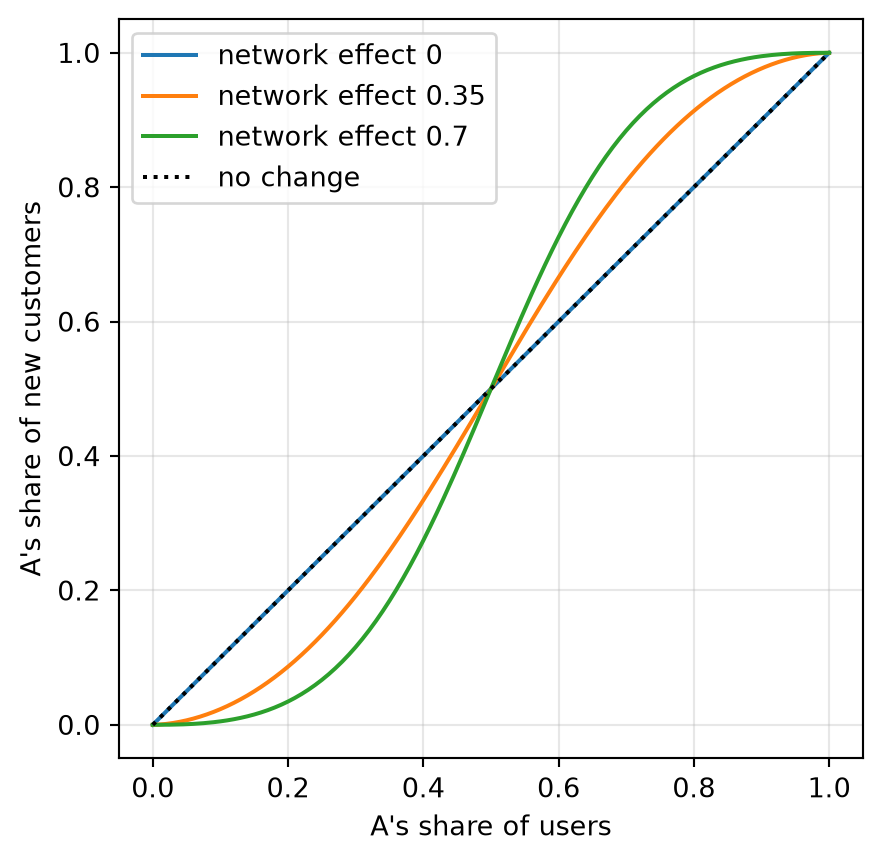

In [6]:
import numpy as np
x = np.linspace(0, 1, 201)                      # A's current share of users
fig, ax = plt.subplots(figsize=(5, 5))
for n in (0, 0.35, 0.7):
    phi = 1 + 2 * n
    ax.plot(x, x**phi / (x**phi + (1 - x)**phi), label=f"network effect {n}")
ax.plot(x, x, "k:", label="no change")
ax.set_xlabel("A's share of users"); ax.set_ylabel("A's share of new customers"); ax.legend(); ax.grid(alpha=0.3)

phi = 1 + 2 * 0.7
for s in (0.3, 0.45, 0.5, 0.55, 0.7):
    print(f"A has {s:.0%} of users -> wins {s**phi / (s**phi + (1 - s)**phi):.0%} of newcomers")

With a network effect the curve is an S that crosses the diagonal three times: at 0, at 50% and at 100%. At 50% the curve is steeper than the diagonal, so a lead of 5 points (55%) wins 62% of newcomers and grows further: the tie is like a ball balanced on an upturned bowl, and any push sends it rolling. At 0 and 100% the curve is flatter than the diagonal, so those are the bottoms of bowls: once there, the market stays. Market Share has three equilibria, two stable and one unstable.

**Try it.** What does the picture look like with no network effect, and what does that tell you about the first run in section 2?

<details><summary>Show a worked answer</summary>

With a network effect of 0 the power is 1, so A's share of newcomers equals its share of users: the curve lies exactly on the diagonal. Every split is an equilibrium, and none is pulled anywhere. That is why A kept its 52.5% for the whole run: nothing amplified or erased the starting lead. In the bowl picture, the floor is flat.
</details>

## 4. When chance picks the winner

In a real market no one starts exactly level: early buyers arrive one at a time, more or less at random. A **Polya urn** is the simplest model of that. Start with one red ball and one blue. Draw a ball, then put it back along with another of the same colour, and repeat. Here a ball's chance of being drawn is its colour's count raised to a power, like attractiveness in Market Share: power 1 is the classic urn, power 2 a strong network effect.

power 1: final red shares [0.22, 0.51, 0.77, 0.92, 0.03, 0.29, 0.15, 0.11]
power 2: final red shares [0.01, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0]


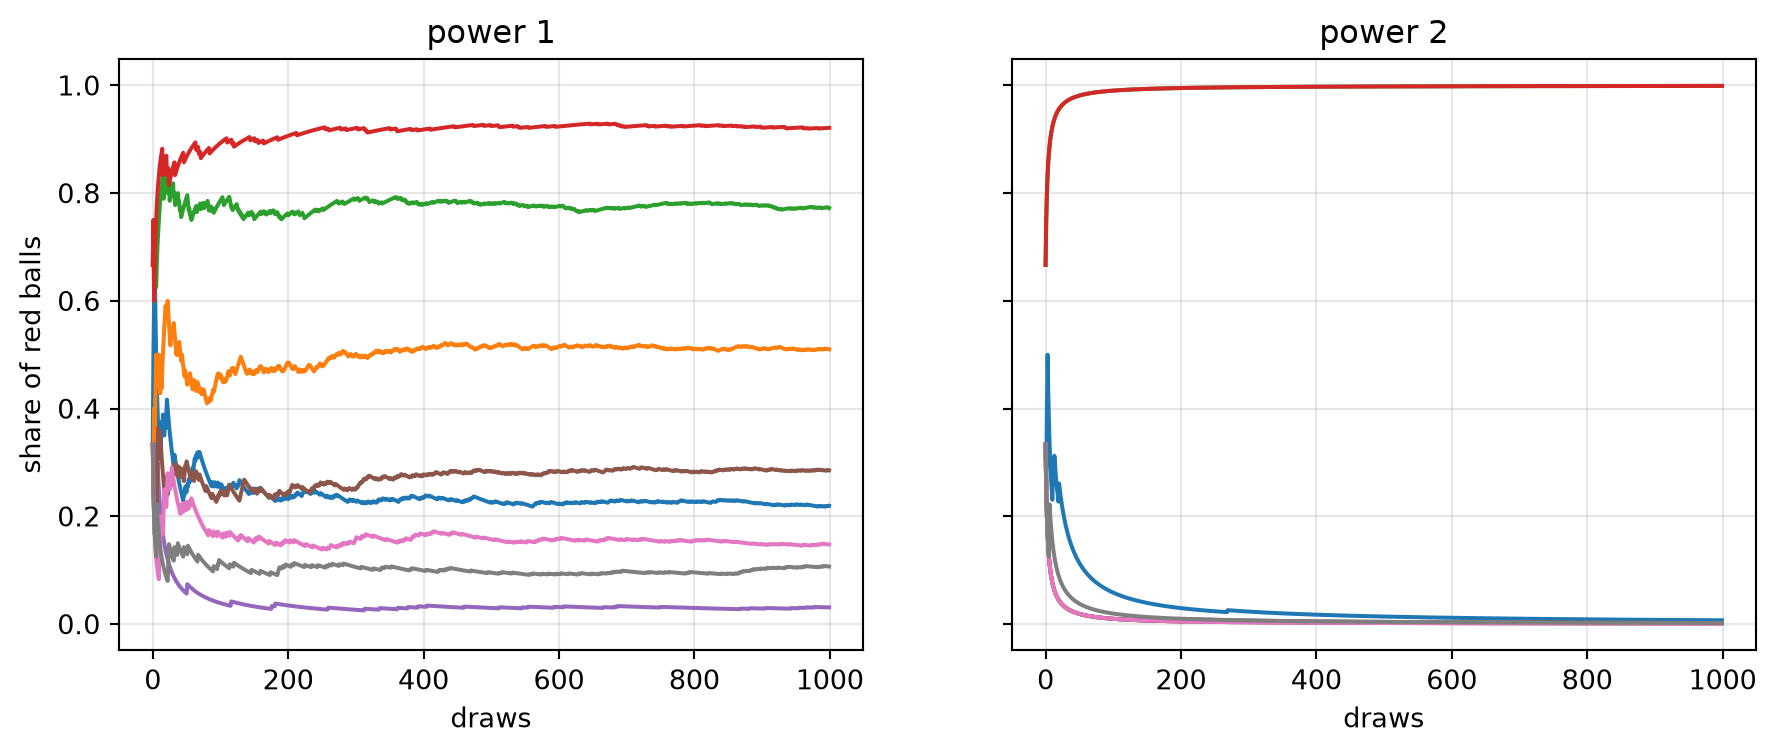

In [7]:
def urn(power, draws=1000, seed=0):
    rng = np.random.default_rng(seed)
    red, blue = 1.0, 1.0
    shares = []
    for _ in range(draws):
        p_red = red**power / (red**power + blue**power)
        if rng.random() < p_red:
            red += 1
        else:
            blue += 1
        shares.append(red / (red + blue))
    return shares

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, power in zip(axes, (1, 2)):
    for seed in range(8):
        ax.plot(urn(power, seed=seed))
    ax.set_title(f"power {power}"); ax.set_xlabel("draws"); ax.grid(alpha=0.3)
axes[0].set_ylabel("share of red balls")

for power in (1, 2):
    print(f"power {power}: final red shares", [round(urn(power, seed=s)[-1], 2) for s in range(8)])

Each line is one history. With power 1, every run settles at a share, but the share is different every time (from 3% to 92% across these eight) and is fixed by the first few draws. With power 2, each run ends with one colour holding almost everything, and which colour wins is a matter of luck. The structure decides that *someone* will dominate; chance decides *who*.

**Try it.** Run 100 histories of each urn. How many end with one colour above 90%, and how many end somewhere between 30% and 70%?

<details><summary>Show a worked answer</summary>

With power 1, 17 of the 100 runs end beyond 90/10 and 42 end between 30% and 70%: the final shares are spread all over. With power 2, all 100 end beyond 90/10 and none in the middle. A strong reinforcing loop removes the middle ground.
</details>

In [8]:
for power in (1, 2):
    finals = [urn(power, seed=s)[-1] for s in range(100)]
    lopsided = sum(f > 0.9 or f < 0.1 for f in finals)
    middle = sum(0.3 < f < 0.7 for f in finals)
    print(f"power {power}: {lopsided} lopsided, {middle} in the middle")

power 1: 17 lopsided, 42 in the middle
power 2: 100 lopsided, 0 in the middle


## Where next

- Back in the app: the [lock-in module](https://waelrash1.github.io/loopbricks/#/learn/lock-in) covers switching costs, growth engines and how lock-in can break.
- The same reinforcing loop, meeting a limit, gives S-shaped growth: see [S-shaped growth](https://waelrash1.github.io/loopbricks/#/learn/s-shaped).
- Market Share returns among the [system archetypes](https://waelrash1.github.io/loopbricks/#/learn/archetypes) as *success to the successful*. For more on path dependence, see Sterman 2000, ch. 10.